In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader

import deep_models.config as c                                       
from deep_models.data import S00MILDataset, load_folds, make_splits  
from deep_models.vae_bncnn import BrainNetCNNVAE
from deep_models.vae_train import init_model

from evaluation import (active_mask, encode_raw_bags, extract_raw_from_loader, flatten_offdiag_bags,
                        get_device, pca_bags, plot_embedding_votes, run_nn_probes, select_dims)


In [ ]:
device = get_device()  
split_k = 5
num_workers = 4
LATENT_DIM = 64

In [ ]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1087  val=132  test=134


In [ ]:
trainset = S00MILDataset(train_idx, max_instances=150, train=True)
valset = S00MILDataset(val_idx, max_instances=150, train=False)
testset = S00MILDataset(test_idx, max_instances=150, train=False)


loader_kw = dict(batch_size=10, num_workers=num_workers, pin_memory=True) 
trainloader = DataLoader(trainset, shuffle=True, **loader_kw)  
valloader = DataLoader(valset, shuffle=False, **loader_kw)
testloader = DataLoader(testset, shuffle=False, **loader_kw) 

In [6]:
raw_tr, y_train = extract_raw_from_loader(trainloader)
raw_va, y_val   = extract_raw_from_loader(valloader)
raw_te, y_test  = extract_raw_from_loader(testloader)

raw_splits = {"train": raw_tr, "val": raw_va, "test": raw_te}

### 1. Baseline: Flattened off-diagonal raw inputs (5 * 17 * 16 = 1360 dims)


In [7]:
bags = {"raw_offdiag": {s: flatten_offdiag_bags(raw_splits[s]) for s in ("train", "val", "test")}}

### 2. Baseline: PCA on flattened off-diagonal raw inputs (64 dims, matching VAE latent_dim)

In [8]:
bags["pca"] = pca_bags(bags["raw_offdiag"], n_components=LATENT_DIM, seed=0)

### 3. Random BrainNetConvVAE (initialized with init_model, NO training)

In [ ]:
torch.manual_seed(0)
vae_rand = BrainNetCNNVAE(latent=LATENT_DIM).to(device)
init_model(vae_rand, trainloader) 
vae_rand.eval()

bags["vae_random_mu"] = {s: encode_raw_bags(vae_rand, raw_splits[s], device=device)[0] for s in ("train", "val", "test")} 

### 4. Trained BrainNetConvVAE

In [ ]:
torch.manual_seed(0)
vae_trained = BrainNetCNNVAE(latent=64, cond_dim=0).to(device)  # match your training args
state_dict = torch.load(f"best_vae_bncnn_split{split_k}.pt", map_location=device, weights_only=True)
vae_trained.load_state_dict(state_dict)
vae_trained.eval()

bags["vae_trained_mu"] = {s: encode_raw_bags(vae_trained, raw_splits[s], device=device)[0] for s in ("train", "val", "test")}

### 5. Trained VAE - active dimensions (threshold for mu_variance 0.1)

In [11]:
mask = active_mask(bags["vae_trained_mu"]["train"], thr=0.1)
print(f"Trained VAE active units: {mask.sum()} / {LATENT_DIM}")
bags["vae_trained_mu_active"] = select_dims(bags["vae_trained_mu"], mask)

Trained VAE active units: 64 / 64


In [12]:
representations = ["raw_offdiag", "pca", "vae_random_mu", "vae_trained_mu", "vae_trained_mu_active"]

In [13]:
rows, artifacts = run_nn_probes(bags=bags,
                                representations=representations,
                                y_train=y_train,
                                y_val=y_val,
                                y_test=y_test,
                                return_artifacts=True,
                                abmil_variants={"ABMIL_linear": None, "ABMIL_h64": 64})
df = pd.DataFrame(rows)

[raw_offdiag] LinearBagProbe  val AUC = 0.699  epoch = 112  test AUC = 0.661
[raw_offdiag] LinearInstanceProbeBagLabels_soft  val AUC = 0.711  epoch = 58  test AUC = 0.685
[raw_offdiag] LinearInstanceProbeBagLabels_vote  val AUC = 0.726  epoch = 58  test AUC = 0.680
[raw_offdiag] ABMIL_linear  val AUC = 0.606  epoch = 14  test AUC = 0.565
[raw_offdiag] ABMIL_h64  val AUC = 0.658  epoch = 10  test AUC = 0.630
[pca] LinearBagProbe  val AUC = 0.650  epoch = 18  test AUC = 0.642
[pca] LinearInstanceProbeBagLabels_soft  val AUC = 0.671  epoch = 30  test AUC = 0.575
[pca] LinearInstanceProbeBagLabels_vote  val AUC = 0.660  epoch = 30  test AUC = 0.565
[pca] ABMIL_linear  val AUC = 0.680  epoch = 4  test AUC = 0.619
[pca] ABMIL_h64  val AUC = 0.668  epoch = 5  test AUC = 0.645
[vae_random_mu] LinearBagProbe  val AUC = 0.653  epoch = 297  test AUC = 0.547
[vae_random_mu] LinearInstanceProbeBagLabels_soft  val AUC = 0.612  epoch = 24  test AUC = 0.565
[vae_random_mu] LinearInstanceProbeBagLabel

## Visualization in 2-dims

In [14]:
embeddings_2d = {rep: TSNE(n_components=2, init="pca", learning_rate="auto", random_state=0).fit_transform(artifacts[rep]["X_val"]) for rep in representations}

In [15]:
val_sizes = np.array([len(b) for b in bags["vae_trained_mu"]["val"]])
exam_ids = np.repeat(np.arange(len(val_sizes)), val_sizes)
window_labels = np.repeat(y_val, val_sizes)

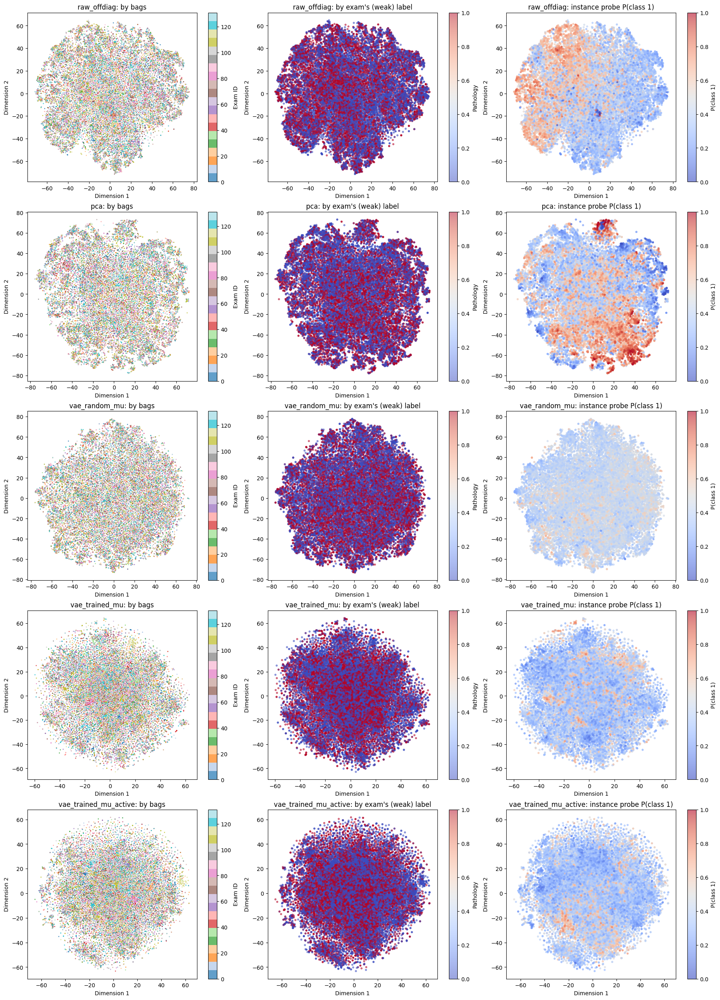

In [16]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="prob")
plt.show()

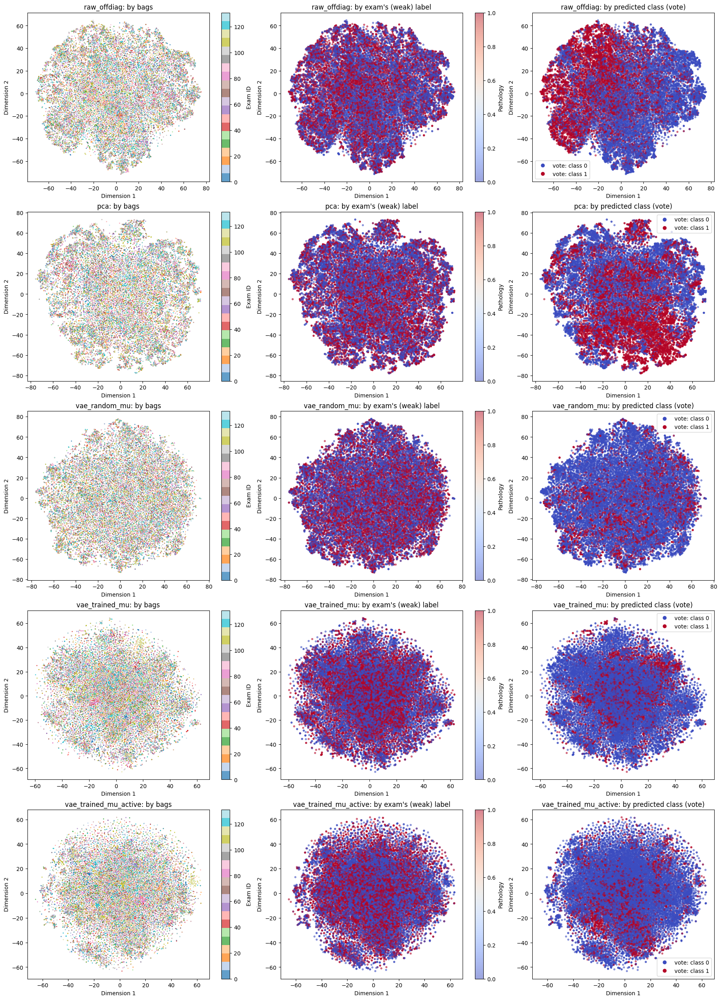

In [17]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="vote")
plt.show()